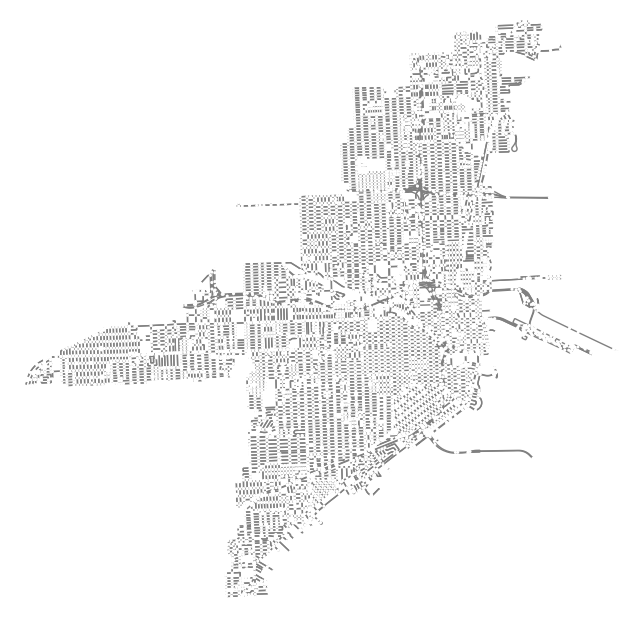

Graph visualization saved as 'miami_road_network.png'


In [23]:
import osmnx as ox

place_name = "Miami, Florida, USA"

graph = ox.graph_from_place(place_name, network_type="drive")

fig, ax = ox.plot_graph(graph, bgcolor="white", node_size=5, edge_color="gray")

output_image_path = "miami_road_network.png"
fig.savefig(output_image_path, dpi=300)
print(f"Graph visualization saved as '{output_image_path}'")

Source Node: 532209018, Target Node: 99351404
Length (miles): 5.579681980193369
Energy consumed (kWh): 2.130434173677432


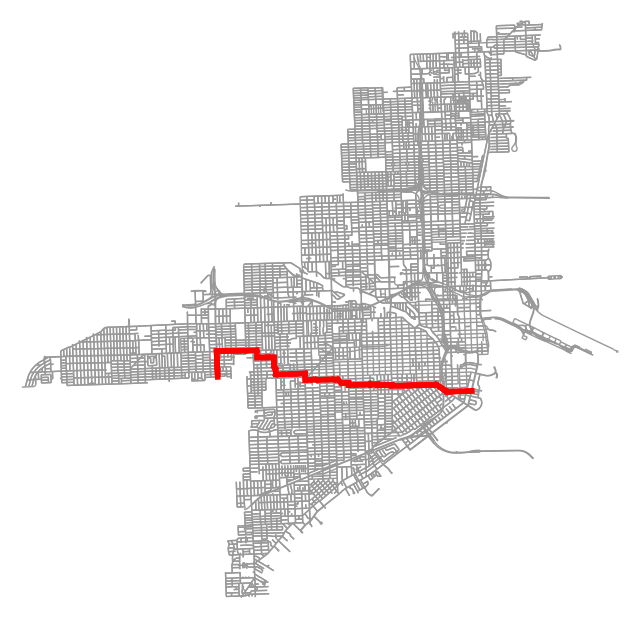

In [42]:
import cvxpy as cp
import networkx as nx
import osmnx as ox
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import LineString

# road network of Miami, FL
place_name = "Miami, Florida, USA"
graph = ox.graph_from_place(place_name, network_type="drive")

# use graph.copy for computation
G = graph.copy()

# source and target by latitude and longitude
source_lat, source_lon = 25.7617, -80.1918  # downtown Miami somewhere
target_lat, target_lon = 25.758949, -80.262994  # somewhere in Coral Gables

source_node = ox.nearest_nodes(graph, X=source_lon, Y=source_lat)
target_node = ox.nearest_nodes(graph, X=target_lon, Y=target_lat)

print(f"Source Node: {source_node}, Target Node: {target_node}")

if not nx.has_path(G, source_node, target_node):
    print("No path exists between source and target. Exiting.")
    exit()

# vectorizing optimization problem for faster computation

# getting edges and nodes
edges = list(G.edges(keys=True))
nodes = list(G.nodes)
num_edges = len(edges)
num_nodes = len(nodes)

# edge weights vector
edge_weights = np.array([G[u][v][k].get('length', 1) for u, v, k in edges])

# flow conservation
incidence_matrix = np.zeros((num_nodes, num_edges))
node_idx = {node: idx for idx, node in enumerate(nodes)}

for edge_idx, (u, v, k) in enumerate(edges): 
    incidence_matrix[node_idx[u], edge_idx] = 1
    incidence_matrix[node_idx[v], edge_idx] = -1

# binary decision variable for edges
x = cp.Variable(num_edges, boolean=True)

# objective function: minimize total path length
objective = cp.Minimize(edge_weights @ x)

# flow constraints
b = np.zeros(num_nodes)
b[node_idx[source_node]] = 1  # flow out of source
b[node_idx[target_node]] = -1  # flow into target

constraints = [incidence_matrix @ x == b]

# solving the optimization problem
problem = cp.Problem(objective, constraints)
problem.solve(solver=cp.GLPK_MI)

# visualization & extracting solution
if problem.status in ["infeasible", "unbounded"]:
    print("No feasible path found.")
    shortest_path = []
else:
    shortest_path_edges = [edges[i] for i in range(num_edges) if x.value[i] > 0.5]

    path_nodes = [shortest_path_edges[0][0]]  # start with the first node
    for u, v, k in shortest_path_edges:
        path_nodes.append(v)  # append the next node along the path

    # calculate total path length (from CVXPY)
    path_length_meters = sum(G[u][v][k].get('length', 1) for u, v, k in shortest_path_edges)
    path_length_miles = path_length_meters / 1609.34

    print(f"Length (miles): {path_length_miles}")

    # energy consumption: kWh/mi = 0.38182100770306 (from data exploration)
    energy_consumed = path_length_miles * 0.38182
    print(f"Energy consumed (kWh): {energy_consumed}")

    # visualize path on map
    fig, ax = ox.plot_graph(G, node_size=0, bgcolor='white', show=False, close=False)

    for u, v, k in shortest_path_edges:
        if G.has_edge(u, v, k):
            edge = G[u][v][k]
            if 'geometry' in edge:
                line = edge['geometry']
            else:
                line = LineString([(G.nodes[u]['x'], G.nodes[u]['y']),
                                  (G.nodes[v]['x'], G.nodes[v]['y'])])
            ax.plot(*line.xy, linewidth=4, color='red')
    plt.show()
